In [1]:
# Timer, Drive mount and helpers, then look at both files without fixing anything
import time, os
t0 = time.time()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from google.colab import drive

time_log, error_log = [], []
def stamp(stage):
    time_log.append((stage, time.strftime("%H:%M:%S")))
    print("TIME:", stage, time.strftime("%H:%M:%S"))

def style():
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                         "axes.titlesize": 11, "axes.labelsize": 10, "figure.dpi": 100})
style()

# Mount Drive and make sure the folder exists
drive.mount("/content/drive")
folder = "/content/drive/MyDrive/Phase4_Final"
os.makedirs(folder, exist_ok=True)

po_raw = pd.read_csv(f"{folder}/day117_purchase_orders.csv")
sm_raw = pd.read_csv(f"{folder}/day117_supplier_master.csv")

print(po_raw.shape, sm_raw.shape)
print(po_raw.dtypes)
print(po_raw.isna().sum())
for c in ["Item", "Warehouse", "Status", "SupplierID"]:
    print(c, po_raw[c].nunique(), "labels:", po_raw[c].value_counts(dropna=False).to_dict())
print("dup PO_ID:", po_raw["PO_ID"].duplicated().sum(), "| dup rows:", po_raw.duplicated().sum())
print(po_raw[["QtyOrdered", "QtyReceived", "UnitCostKES"]].describe().T[["min", "max"]])
print(sm_raw)
print("master dup rows:", sm_raw.duplicated().sum())
stamp("Setup and inspect")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(605, 12) (9, 5)
PO_ID            object
OrderDate        object
PromisedDate     object
ReceiptDate      object
SupplierID       object
Item             object
Category         object
Warehouse        object
QtyOrdered        int64
QtyReceived     float64
UnitCostKES     float64
Status           object
dtype: object
PO_ID            0
OrderDate        0
PromisedDate     0
ReceiptDate     47
SupplierID       0
Item             0
Category         0
Warehouse        0
QtyOrdered       0
QtyReceived     34
UnitCostKES      6
Status           0
dtype: int64
Item 16 labels: {'Paint Tins': 59, 'Steel Bolts': 56, 'Pallets': 56, 'Detergent': 52, 'Shrink Wrap': 51, 'Cartons': 50, 'Fertiliser': 50, 'Solvent': 49, 'Sugar': 47, 'Maize Flour': 45, 'Cement Bags': 43, 'Cooking Oil': 43, 'detergent': 1, ' Solvent': 1, 'cartons': 1, 'PAINT TINS': 1}
Warehouse 13 labels: {'Kis

In [2]:
# Every fix has a why-comment, a count, and an assert
po = po_raw.copy()
n0 = len(po)

# Why: ' Kisumu ' and 'MOMBASA' split one group into several
for c in ["Item", "Warehouse", "Status"]:
    po[c] = po[c].str.strip().str.title()
sm = sm_raw.copy()
sm["SupplierName"] = sm["SupplierName"].str.strip()

# Why: text dates can't be subtracted or grouped by month
for c in ["OrderDate", "PromisedDate", "ReceiptDate"]:
    po[c] = pd.to_datetime(po[c], errors="raise")

# Why: duplicates double-count spend; a duplicate SUP03 in the master would fan out the merge
n_dup = po.duplicated().sum()
po = po.drop_duplicates().reset_index(drop=True)
n_sm_dup = sm.duplicated().sum()
sm = sm.drop_duplicates().reset_index(drop=True)

# Why: QtyReceived is exactly 1/100 of QtyOrdered on these rows, so it's a x100 typo
typo = (po["QtyOrdered"] > 1000) & (po["QtyOrdered"] == po["QtyReceived"] * 100)
n_qty_fix = typo.sum()
po.loc[typo, "QtyOrdered"] = po.loc[typo, "QtyOrdered"] / 100

# Why: a negative price is a sign typo (the Pallets value is close to the Pallets median)
n_neg = (po["UnitCostKES"] < 0).sum()
po["UnitCostKES"] = po["UnitCostKES"].abs()

# Why: more than 5x the item median can't be a real price, so blank it instead of keeping or zeroing it
item_med = po["UnitCostKES"].groupby(po["Item"]).transform("median")
bad_cost = po["UnitCostKES"] > 5 * item_med
n_bad_cost = bad_cost.sum()
po.loc[bad_cost, "UnitCostKES"] = np.nan

# Why: item prices are stable, so the item median is a fair fill; flagged so it can be audited
po["cost_imputed"] = po["UnitCostKES"].isna() & po["Status"].isin(["Received", "Partial"])
n_cost_imp = po["cost_imputed"].sum()
po["UnitCostKES"] = po["UnitCostKES"].fillna(item_med)

# Why: receipt before order means the two dates were swapped; swapping gives a normal 7-9 day promise window
bad_ord = po["ReceiptDate"] < po["OrderDate"]
n_bad_ord = bad_ord.sum()
po.loc[bad_ord, ["OrderDate", "ReceiptDate"]] = po.loc[bad_ord, ["ReceiptDate", "OrderDate"]].values

# Why: no proxy for a missing received quantity, so leave NaN, never 0 (0 would say nothing arrived)
n_qty_na = (po["Status"].isin(["Received", "Partial"]) & po["QtyReceived"].isna()).sum()

# Derived columns, using the exercise definitions exactly (spend uses QtyReceived)
po["Received_or_Partial"] = po["Status"].isin(["Received", "Partial"])
po["SpendKES"] = np.where(po["Received_or_Partial"], po["QtyReceived"] * po["UnitCostKES"], np.nan)
po["OnTime"] = (po["ReceiptDate"] <= po["PromisedDate"]).astype(float).where(po["Received_or_Partial"])
po["LeadDays"] = (po["ReceiptDate"] - po["OrderDate"]).dt.days.where(po["Received_or_Partial"])
fr = po["Received_or_Partial"] & po["QtyReceived"].notna()
po["qty_rec_fr"] = po["QtyReceived"].where(fr)
po["qty_ord_fr"] = po["QtyOrdered"].where(fr)
po["SpendMonth"] = po["ReceiptDate"].dt.to_period("M")

# Proof: counts before and after
print(pd.DataFrame({"fix": ["orders (rows)", "duplicate orders dropped", "master duplicates dropped",
        "item labels", "warehouse labels", "status labels", "qty x100 fixed", "negative costs flipped",
        "cost outliers -> NaN", "costs imputed (flagged)", "reversed dates swapped", "received, qty missing"],
    "before": [n0, "", "", po_raw["Item"].nunique(), po_raw["Warehouse"].nunique(), po_raw["Status"].nunique(),
               "", "", "", "", "", ""],
    "after": [len(po), n_dup, n_sm_dup, po["Item"].nunique(), po["Warehouse"].nunique(),
              po["Status"].nunique(), n_qty_fix, n_neg, n_bad_cost, n_cost_imp, n_bad_ord, n_qty_na]}).to_string(index=False))

assert len(po) == 600 and po["PO_ID"].is_unique and sm["SupplierID"].is_unique
assert po["Item"].nunique() == 12 and po["Warehouse"].nunique() == 4 and po["Status"].nunique() == 4
assert (po["UnitCostKES"] > 0).all()
assert po["QtyOrdered"].max() < 1000
assert ((po["QtyReceived"] <= po["QtyOrdered"]) | po["QtyReceived"].isna()).all()
assert (po.loc[po["Received_or_Partial"], "LeadDays"].dropna() >= 0).all()
assert (po["PromisedDate"] >= po["OrderDate"]).all()
assert po.loc[po["Status"].isin(["Open", "Cancelled"]), "ReceiptDate"].isna().all()
assert po.loc[po["Received_or_Partial"], "ReceiptDate"].notna().all()
assert po["SpendKES"].notna().sum() == po["Received_or_Partial"].sum() - n_qty_na
assert not sm["SupplierName"].str.startswith(" ").any() and not sm["SupplierName"].str.endswith(" ").any()
stamp("Clean")

                      fix before  after
            orders (rows)    605    600
 duplicate orders dropped             5
master duplicates dropped             1
              item labels     16     12
         warehouse labels     13      4
            status labels      7      4
           qty x100 fixed             3
   negative costs flipped             1
     cost outliers -> NaN             2
  costs imputed (flagged)             7
   reversed dates swapped             5
    received, qty missing             5
TIME: Clean 14:55:11


In [3]:
# Merge, scorecard, pivot, monthly forecast, NumPy stats, then reconcile all totals
# Left join keeps every order; unknown suppliers stay as a labelled row because their spend is real
n_before = len(po)
df = po.merge(sm, on="SupplierID", how="left", validate="m:1", indicator=True)
unmatched = df["_merge"] == "left_only"
print("unmatched orders:", unmatched.sum(), "| ids:", df.loc[unmatched, "SupplierID"].unique(),
      "| spend KES", round(df.loc[unmatched, "SpendKES"].sum()))
df["SupplierName"] = df["SupplierName"].fillna("Unmatched (" + df["SupplierID"] + ")")
df = df.drop(columns="_merge")
print("rows before/after merge:", n_before, len(df))
assert len(df) == n_before == 600
assert df["SupplierName"].notna().all() and df.loc[unmatched, "SupplierID"].eq("SUP99").all()
stamp("Merge")

# Scorecard: Received and Partial orders only; fill rate is a ratio of sums
rp = df[df["Received_or_Partial"]]
sc = rp.groupby("SupplierName").agg(
    Orders=("PO_ID", "count"),
    SpendKES=("SpendKES", "sum"),
    AvgLeadDays=("LeadDays", "mean"),
    OnTimePct=("OnTime", lambda s: 100 * s.mean()),
    _rec=("qty_rec_fr", "sum"), _ord=("qty_ord_fr", "sum"))
sc["SpendShare%"] = 100 * sc["SpendKES"] / sc["SpendKES"].sum()
sc["FillRatePct"] = 100 * sc["_rec"] / sc["_ord"]
sc = sc.drop(columns=["_rec", "_ord"]).sort_values("SpendKES", ascending=False)
sc = sc[["Orders", "SpendKES", "SpendShare%", "AvgLeadDays", "OnTimePct", "FillRatePct"]].round(2)
print(sc.to_string())
assert np.isclose(sc["SpendShare%"].sum(), 100, atol=0.1) and sc["Orders"].sum() == rp.shape[0]
assert sc["FillRatePct"].between(80, 100).all()          # a fill rate near 35% would mean outliers are still in
stamp("Scorecard")

# Pivot: Category x Warehouse spend, with totals for the reconcile
pivot = pd.pivot_table(rp, index="Category", columns="Warehouse", values="SpendKES",
                       aggfunc="sum", margins=True, margins_name="Total").round(0)
print(pivot)

# Monthly: receipt month; the last month is partial, so the trend uses the 12 full months only
months = pd.period_range(rp["SpendMonth"].min(), rp["SpendMonth"].max(), freq="M")
monthly = rp.groupby("SpendMonth")["SpendKES"].sum().reindex(months, fill_value=0)
last_partial = rp["ReceiptDate"].max() < rp["ReceiptDate"].max().to_period("M").end_time.normalize()
fit = monthly.iloc[:-1] if last_partial else monthly
roll3 = fit.rolling(3).mean()
x = np.arange(len(fit))
slope, intercept = np.polyfit(x, fit.values, 1)
fx = np.arange(len(fit), len(fit) + 3)
fc_months = pd.period_range(fit.index[-1] + 1, periods=3, freq="M")
forecast = pd.Series(intercept + slope * fx, index=fc_months)
print(monthly.to_frame("SpendKES").assign(Roll3=roll3).round(0))
print("slope KES/month:", round(slope)); print(forecast.round(0))
assert last_partial and len(fit) == 12 and (forecast > 0).all()
assert monthly.max() < 6e6                               # a 15M month would mean outliers are still in

# NumPy: correlation over the 8 master suppliers; P90 lead time over orders with a valid LeadDays
m8 = sc[~sc.index.str.startswith("Unmatched")]
corr = np.corrcoef(m8["OnTimePct"], m8["FillRatePct"])[0, 1]
lead = rp["LeadDays"].dropna().to_numpy()
p90 = np.percentile(lead, 90)
share_above = 100 * (lead > p90).mean()
print(f"corr(OnTime, FillRate) = {corr:.2f} (n={len(m8)} suppliers)")
print(f"P90 lead = {p90:.1f} days; {share_above:.1f}% of orders above it (n={len(lead)})")

# Reconcile: one total, four routes
total = rp["SpendKES"].sum()
assert np.isclose(sc["SpendKES"].sum(), total, atol=1)
assert np.isclose(monthly.sum(), total, atol=1)
assert np.isclose(pivot.loc["Total", "Total"], total, atol=20)      # pivot is rounded to 0 dp
assert np.isclose(df["SpendKES"].sum(), total, atol=1)
print(f"Reconciled: total spend KES {total:,.0f}")
stamp("Analyse")

unmatched orders: 3 | ids: ['SUP99'] | spend KES 345065
rows before/after merge: 600 600
TIME: Merge 14:55:15
                          Orders    SpendKES  SpendShare%  AvgLeadDays  OnTimePct  FillRatePct
SupplierName                                                                                  
Rift Valley Packaging         95  7044782.83        18.02         7.24      64.21        98.16
Nakuru Plastics               89  6362056.75        16.27         9.55      39.33        94.09
Nairobi Industrial Parts      84  5863328.65        14.99         9.54      61.90        95.36
Mombasa Imports Ltd           77  4825167.61        12.34        15.39      40.26        96.25
Eldoret Foods Co              67  4775949.54        12.21         7.03      44.78        96.65
Thika Textiles                43  3437745.98         8.79        12.98      41.86        96.05
Kisumu Agro Supplies          55  3361732.77         8.60        12.02      29.09        91.45
Coast Chemicals               41  3

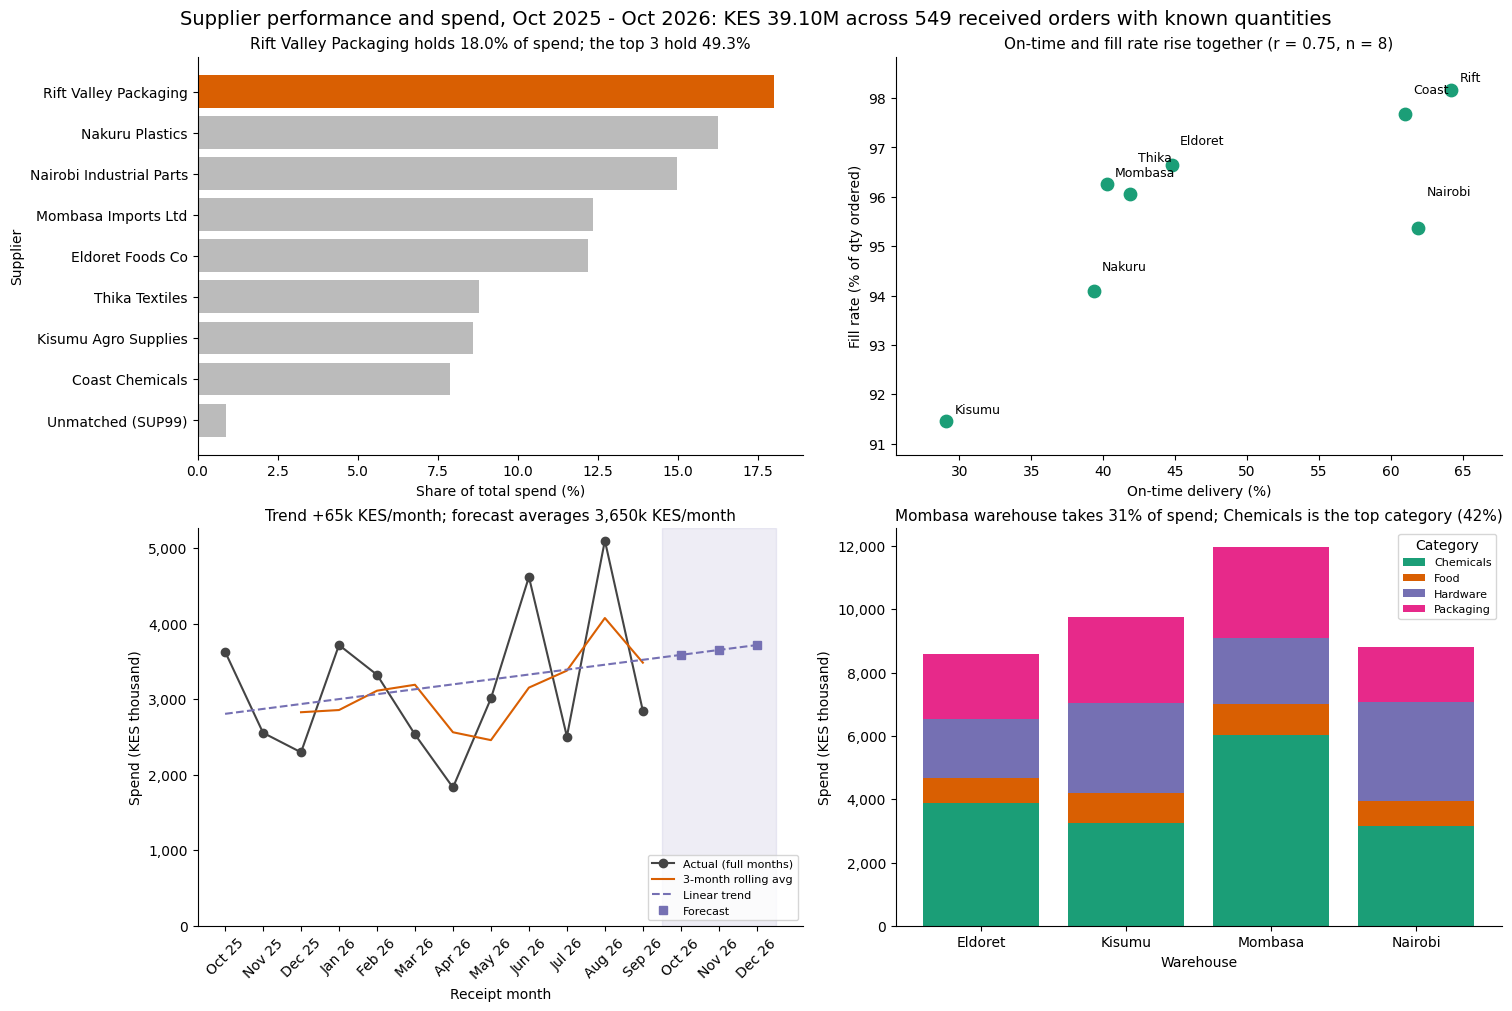

TIME: Figure 14:55:22


In [4]:
# 2x2 with f-string titles; saved to the Drive folder
kfmt = FuncFormatter(lambda v, _: f"{v/1e3:,.0f}")
s1 = sc["SpendShare%"]; top1, top3 = s1.index[0], s1.head(3).sum()
fig, ax = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

a = ax[0, 0]; r = s1.sort_values()
a.barh(r.index, r.values, color=["#d95f02" if i == top1 else "#bbbbbb" for i in r.index])
a.set_title(f"{top1} holds {s1.iloc[0]:.1f}% of spend; the top 3 hold {top3:.1f}%")
a.set_xlabel("Share of total spend (%)"); a.set_ylabel("Supplier")

b = ax[0, 1]
b.scatter(m8["OnTimePct"], m8["FillRatePct"], s=80, color="#1b9e77")
for i, (name, row) in enumerate(m8.iterrows()):
    b.annotate(name.split()[0], (row["OnTimePct"], row["FillRatePct"]),
               xytext=(6, 6 + 9 * (i % 3)), textcoords="offset points", fontsize=9)
direction = "rise together" if corr > 0 else "move in opposite directions"
b.set_title(f"On-time and fill rate {direction} (r = {corr:.2f}, n = {len(m8)})")
b.margins(x=0.1, y=0.1)
b.set_xlabel("On-time delivery (%)"); b.set_ylabel("Fill rate (% of qty ordered)")

c = ax[1, 0]
allm = list(fit.index) + list(fc_months)
pos_ = np.arange(len(allm))
c.plot(pos_[:len(fit)], fit.values, marker="o", color="#444", label="Actual (full months)")
c.plot(pos_[:len(fit)], roll3.values, color="#d95f02", label="3-month rolling avg")
c.plot(pos_, intercept + slope * pos_, "--", color="#7570b3", label="Linear trend")
c.plot(pos_[len(fit):], forecast.values, marker="s", color="#7570b3", linestyle="none", label="Forecast")
c.axvspan(len(fit) - 0.5, len(allm) - 0.5, color="#7570b3", alpha=0.12)
c.set_xticks(pos_); c.set_xticklabels([p.strftime("%b %y") for p in allm], rotation=45)
c.yaxis.set_major_formatter(kfmt); c.set_ylim(0)
c.set_title(f"Trend {slope/1e3:+,.0f}k KES/month; forecast averages {forecast.mean()/1e3:,.0f}k KES/month")
c.set_xlabel("Receipt month"); c.set_ylabel("Spend (KES thousand)"); c.legend(fontsize=8, loc="lower right")

d = ax[1, 1]; pv = pivot.drop(index="Total", columns="Total")
bottom = np.zeros(len(pv.columns))
for cat, col in zip(pv.index, ["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]):
    d.bar(pv.columns, pv.loc[cat].values, bottom=bottom, label=cat, color=col)
    bottom += pv.loc[cat].values
tw = pv.sum().idxmax(); tc = pv.sum(axis=1).idxmax()
d.set_title(f"{tw} warehouse takes {100*pv.sum().max()/total:.0f}% of spend; "
            f"{tc} is the top category ({100*pv.sum(axis=1).max()/total:.0f}%)")
d.yaxis.set_major_formatter(kfmt); d.set_xlabel("Warehouse"); d.set_ylabel("Spend (KES thousand)")
d.legend(title="Category", fontsize=8)

n_spend = rp["SpendKES"].notna().sum()
fig.suptitle(f"Supplier performance and spend, Oct 2025 - Oct 2026: "
             f"KES {total/1e6:.2f}M across {n_spend} received orders with known quantities", fontsize=14)

plt.show()
stamp("Figure")

In [5]:
# Numbers first, then the finding; every figure comes from a variable and the limit is about the data
print(sc[["SpendShare%", "OnTimePct", "FillRatePct", "AvgLeadDays"]])
print(f"top3 share {top3:.1f}% | corr {corr:.2f} | P90 {p90:.1f}d, {share_above:.1f}% above | "
      f"forecast avg KES {forecast.mean():,.0f} | slope KES {slope:,.0f}/month")

rv, cc = sc.loc["Rift Valley Packaging"], sc.loc["Coast Chemicals"]
nk, ka = sc.loc["Nakuru Plastics"], sc.loc["Kisumu Agro Supplies"]

finding = (
    f"Keep Rift Valley Packaging: it has the biggest spend share ({rv['SpendShare%']:.1f}%) and is reliable "
    f"({rv['OnTimePct']:.1f}% on time, {rv['FillRatePct']:.1f}% fill rate). "
    f"Grow Coast Chemicals: it is reliable ({cc['OnTimePct']:.1f}% on time) but only has {cc['SpendShare%']:.1f}% of spend, "
    f"so shift orders to it, planning for its {cc['AvgLeadDays']:.1f}-day lead time. "
    f"Review Nakuru Plastics ({nk['OnTimePct']:.1f}% on time with {nk['SpendShare%']:.1f}% of spend) "
    f"and Kisumu Agro Supplies ({ka['OnTimePct']:.1f}% on time). "
    f"The top 3 suppliers hold {top3:.1f}% of spend, and spend is forecast at about KES {forecast.mean()/1e6:.2f}M a month. "
    f"Limit: this is only {len(m8)} suppliers and a straight-line forecast over {len(fit)} noisy months, "
    f"so treat the forecast as a rough guide."
)
print(finding)
stamp("Finding")

                          SpendShare%  OnTimePct  FillRatePct  AvgLeadDays
SupplierName                                                              
Rift Valley Packaging           18.02      64.21        98.16         7.24
Nakuru Plastics                 16.27      39.33        94.09         9.55
Nairobi Industrial Parts        14.99      61.90        95.36         9.54
Mombasa Imports Ltd             12.34      40.26        96.25        15.39
Eldoret Foods Co                12.21      44.78        96.65         7.03
Thika Textiles                   8.79      41.86        96.05        12.98
Kisumu Agro Supplies             8.60      29.09        91.45        12.02
Coast Chemicals                  7.90      60.98        97.67        15.39
Unmatched (SUP99)                0.88      33.33        90.01         9.67
top3 share 49.3% | corr 0.75 | P90 15.0d, 9.2% above | forecast avg KES 3,650,386 | slope KES 65,001/month
Keep Rift Valley Packaging: it has the biggest spend share (18.0%) a

In [6]:
# Save the clean files and the figure into the Drive folder, then list it
os.makedirs(folder, exist_ok=True)
df.to_csv(folder + "/day117_purchase_orders_clean.csv", index=False)
sm.to_csv(folder + "/day117_supplier_master_clean.csv", index=False)
fig.savefig(folder + "/day117_supplier_report.png", dpi=150, bbox_inches="tight")
print(os.listdir(folder))
stamp("Save")

['day117_purchase_orders.csv', 'day117_supplier_master.csv', 'day117_purchase_orders_clean.csv', 'day117_supplier_master_clean.csv', 'day117_supplier_report.png']
TIME: Save 14:55:33


In [7]:
# Run after Restart & Run All
print(f"Elapsed: {(time.time() - t0) / 60:.1f} minutes")
print(time_log)

Elapsed: 0.6 minutes
[('Setup and inspect', '14:55:06'), ('Clean', '14:55:11'), ('Merge', '14:55:15'), ('Scorecard', '14:55:15'), ('Analyse', '14:55:15'), ('Figure', '14:55:22'), ('Finding', '14:55:28'), ('Save', '14:55:33')]


In [10]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'day117_supplier_master.csv', 'drive', 'day117_purchase_orders.csv', 'sample_data']


In [11]:
import glob
for f in glob.glob('/content/drive/MyDrive/**/day117*', recursive=True):
    print(f)

/content/drive/MyDrive/Phase4_Final/day117_purchase_orders.csv
/content/drive/MyDrive/Phase4_Final/day117_supplier_master.csv
/content/drive/MyDrive/Phase4_Final/day117_purchase_orders_clean.csv
/content/drive/MyDrive/Phase4_Final/day117_supplier_master_clean.csv
/content/drive/MyDrive/Phase4_Final/day117_supplier_report.png
